In [11]:
import pandas as pd

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

# Steel Plate Faults - EDA Checklist

## 1. 데이터 불러오기 및 기본 구조 확인
- [ ] 공통 `load_data()`로 Train 데이터 불러오기
- [ ] Train 데이터 shape 확인
- [ ] Feature 목록 및 dtype 확인
- [ ] 기초 통계량 확인

## 2. Target 분포 확인
- [ ] 7개 Class별 데이터 수 확인
- [ ] Class별 비율 확인
- [ ] Target 분포 시각화
- [ ] 클래스 불균형 정도 정리

## 3. 데이터 품질 확인
- [ ] 결측치 확인
- [ ] 중복 데이터 확인
- [ ] 상수 / 거의 변화가 없는 Feature 확인
- [ ] 수치형 Feature의 범위 및 이상값 후보 확인
- [ ] Target leakage 가능성이 있는 Feature 확인

## 4. Feature 분포 탐색
- [ ] 주요 Feature의 기본 분포 확인
- [ ] 왜도 / 극단값이 큰 Feature 확인
- [ ] Feature 간 scale 차이 확인
- [ ] Scaling / 변환 필요성 판단

## 5. Feature 간 관계 확인
- [ ] 주요 Feature 간 상관관계 확인
- [ ] 강한 상관관계를 가진 Feature 확인
- [ ] 원본 Feature와 파생 Feature의 중복 정보 가능성 확인

## 6. Feature와 Target 관계 확인
- [ ] 위치 관련 Feature의 Class별 차이 확인
- [ ] 크기 / 면적 관련 Feature의 Class별 차이 확인
- [ ] 형태 관련 Feature의 Class별 차이 확인
- [ ] 밝기 관련 Feature의 Class별 차이 확인
- [ ] 강판 / 설비 관련 Feature의 Class별 차이 확인
- [ ] Class 구분에 특징적인 패턴이 보이는 Feature 정리

## 7. Other_Faults 탐색
- [ ] Other_Faults와 나머지 Class의 주요 Feature 분포 비교
- [ ] Other_Faults의 분포 범위 / 변동성 확인
- [ ] 내부에 여러 패턴이 존재할 가능성이 있는지 탐색
- [ ] 추가 군집 분석 필요성 판단

## 8. EDA 결과 정리 및 모델링 전 결정
- [ ] 주요 EDA 발견사항 정리
- [ ] 실제 처리할 데이터 품질 문제 결정
- [ ] Feature 제외 여부 결정
- [ ] Scaling 등 모델별 전처리 방향 정리
- [ ] Baseline에서 확인할 문제 정의

In [12]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
SRC_DIR = PROJECT_ROOT / "src"

sys.path.append(str(SRC_DIR))

from load_data import load_data

In [13]:
X_train, X_test, y_train, y_test = load_data()

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

display(X_train.head())
display(y_train.head())

X_train shape: (1552, 27)
y_train shape: (1552,)


,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,...,Outside_X_Index,Edges_X_Index,Edges_Y_Index,Outside_Global_Index,LogOfAreas,Log_X_Index,Log_Y_Index,Orientation_Index,Luminosity_Index,SigmoidOfAreas
480,41,190,1799909,1800071,11388,705,420,1311391,36,140,...,0.1063,0.2113,0.3857,1.0000,4.0564,2.1732,2.2095,0.0803,-0.1003,1.0000
1190,896,904,801872,801889,65,12,17,7974,113,135,...,0.0059,0.6667,1.0000,1.0000,1.8129,0.9031,1.2305,0.5294,-0.0416,0.2482
866,38,49,735612,735624,113,11,12,12652,93,130,...,0.0064,1.0000,1.0000,1.0000,2.0531,1.0414,1.0792,0.0833,-0.1253,0.2432
431,41,215,1157189,1157378,16584,821,498,1936241,25,143,...,0.1245,0.2119,0.3795,1.0000,4.2197,2.2406,2.2765,0.0794,-0.0879,1.0000
434,39,212,1185602,1185752,13387,763,425,1546189,29,141,...,0.1238,0.2267,0.3529,0.0000,4.1267,2.2380,2.1761,-0.1329,-0.0977,1.0000


480     K_Scatch
1190       Bumps
866        Bumps
431     K_Scatch
434     K_Scatch
dtype: str

In [14]:
# 1. 기본 크기
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

# 2. Feature 목록
print("\n[Feature 목록]")
print(X_train.columns.tolist())

# 3. 데이터 타입
print("\n[데이터 타입]")
display(X_train.dtypes.value_counts())
display(X_train.dtypes)

# 4. 기본 통계
display(X_train.describe().T)

X_train shape: (1552, 27)
y_train shape: (1552,)

[Feature 목록]
['X_Minimum', 'X_Maximum', 'Y_Minimum', 'Y_Maximum', 'Pixels_Areas', 'X_Perimeter', 'Y_Perimeter', 'Sum_of_Luminosity', 'Minimum_of_Luminosity', 'Maximum_of_Luminosity', 'Length_of_Conveyer', 'TypeOfSteel_A300', 'TypeOfSteel_A400', 'Steel_Plate_Thickness', 'Edges_Index', 'Empty_Index', 'Square_Index', 'Outside_X_Index', 'Edges_X_Index', 'Edges_Y_Index', 'Outside_Global_Index', 'LogOfAreas', 'Log_X_Index', 'Log_Y_Index', 'Orientation_Index', 'Luminosity_Index', 'SigmoidOfAreas']

[데이터 타입]


int64      14
float64    13
Name: count, dtype: int64

X_Minimum                  int64
X_Maximum                  int64
Y_Minimum                  int64
Y_Maximum                  int64
Pixels_Areas               int64
X_Perimeter                int64
Y_Perimeter                int64
Sum_of_Luminosity          int64
Minimum_of_Luminosity      int64
Maximum_of_Luminosity      int64
Length_of_Conveyer         int64
TypeOfSteel_A300           int64
TypeOfSteel_A400           int64
Steel_Plate_Thickness      int64
Edges_Index              float64
Empty_Index              float64
Square_Index             float64
Outside_X_Index          float64
Edges_X_Index            float64
Edges_Y_Index            float64
Outside_Global_Index     float64
LogOfAreas               float64
Log_X_Index              float64
Log_Y_Index              float64
Orientation_Index        float64
Luminosity_Index         float64
SigmoidOfAreas           float64
dtype: object

,count,mean,std,min,25%,50%,75%,max
X_Minimum,"1,552.0000",562.0509,515.2177,0.0000,52.7500,405.5000,"1,038.7500","1,705.0000"
X_Maximum,"1,552.0000",609.5696,492.2804,4.0000,192.7500,445.0000,"1,061.5000","1,713.0000"
Y_Minimum,"1,552.0000","1,662,716.6437","1,811,260.0185","6,712.0000","462,923.5000","1,188,619.0000","2,182,183.5000","12,987,661.0000"
Y_Maximum,"1,552.0000","1,662,761.3499","1,811,258.4190","6,724.0000","462,947.2500","1,188,705.5000","2,182,200.2500","12,987,692.0000"
Pixels_Areas,"1,552.0000","1,870.0831","4,007.8558",2.0000,85.0000,170.5000,822.5000,"37,334.0000"
X_Perimeter,"1,552.0000",107.9929,192.1300,2.0000,15.0000,26.5000,83.2500,"1,275.0000"
Y_Perimeter,"1,552.0000",74.5380,119.2024,1.0000,13.0000,25.0000,80.0000,903.0000
Sum_of_Luminosity,"1,552.0000","206,718.6424","459,112.7242",250.0000,"9,548.7500","19,125.0000","83,647.2500","3,918,209.0000"
Minimum_of_Luminosity,"1,552.0000",84.5064,32.4565,0.0000,62.0000,90.0000,106.0000,203.0000
Maximum_of_Luminosity,"1,552.0000",130.1952,18.9798,37.0000,124.0000,127.0000,140.0000,253.0000


#### 데이터 기본 구조 확인
Train 데이터는 1,552개 관측치와 27개 Feature로 구성되어 있으며, Target은 단일 클래스 라벨 형태이다. Feature별 값의 범위가 크게 달라 모델에 따라 Scaling 필요성을 검토할 필요가 있다. 일부 크기·둘레·밝기 관련 변수에서는 평균과 중앙값 및 최대값의 차이가 크게 나타나 치우친 분포 가능성이 확인되었으나, 실제 이상치 여부와 처리 필요성은 분포 및 Target과의 관계를 추가 확인한 뒤 판단한다. 또한 원본 크기 변수와 로그 변환 변수 등 유사 정보를 포함할 가능성이 있는 Feature는 이후 관계 분석에서 확인한다.

In [15]:
# 클래스별 개수
target_count = y_train.value_counts()

# 클래스별 비율
target_ratio = y_train.value_counts(normalize=True) * 100

target_summary = pd.DataFrame({
    "Count": target_count,
    "Ratio(%)": target_ratio
})

target_summary["Ratio(%)"] = target_summary["Ratio(%)"].round(2)

display(target_summary)

,Count,Ratio(%)
Other_Faults,538,34.6600
Bumps,321,20.6800
K_Scatch,313,20.1700
Z_Scratch,152,9.7900
Pastry,126,8.1200
Stains,58,3.7400
Dirtiness,44,2.8400


In [16]:
imbalance_ratio = target_count.max() / target_count.min()

print(f"가장 많은 클래스: {target_count.idxmax()} ({target_count.max()}개)")
print(f"가장 적은 클래스: {target_count.idxmin()} ({target_count.min()}개)")
print(f"최대/최소 클래스 비율: {imbalance_ratio:.2f}배")

가장 많은 클래스: Other_Faults (538개)
가장 적은 클래스: Dirtiness (44개)
최대/최소 클래스 비율: 12.23배


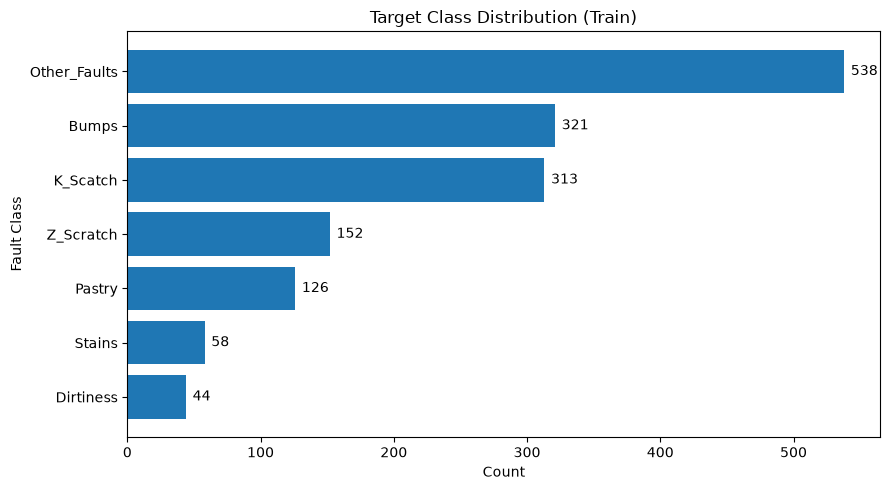

In [17]:
import matplotlib.pyplot as plt

target_summary_plot = target_summary.sort_values("Count", ascending=True)

plt.figure(figsize=(9, 5))

bars = plt.barh(
    target_summary_plot.index,
    target_summary_plot["Count"]
)

for bar, count in zip(bars, target_summary_plot["Count"]):
    plt.text(
        bar.get_width() + 5,
        bar.get_y() + bar.get_height() / 2,
        f"{count}",
        va="center"
    )

plt.xlabel("Count")
plt.ylabel("Fault Class")
plt.title("Target Class Distribution (Train)")
plt.tight_layout()
plt.show()

#### Target 분포 확인 결과
Train 데이터에서 Other_Faults가 538건(34.66%)으로 가장 많고, Dirtiness가 44건(2.84%)으로 가장 적어 최대/최소 클래스 간 약 12.23배 차이가 확인되었다. 상위 3개 클래스가 전체 Train 데이터의 약 75.5%를 차지하는 등 클래스 불균형이 존재한다. 따라서 전체 정확도만으로 모델을 평가할 경우 다수 클래스의 성능이 평가 결과를 주도할 가능성이 있어, 각 클래스의 F1을 동일한 비중으로 반영하는 Macro F1을 핵심 평가 지표로 사용하는 것이 적절하다. 다만 소수 클래스의 실제 분류 난이도는 표본 수만으로 판단하지 않고 이후 Feature 관계 및 Baseline의 클래스별 성능을 통해 확인한다.

In [18]:
# 결측치 확인
print("전체 결측치 수:", X_train.isna().sum().sum())

missing_cols = X_train.isna().sum()
print("\n결측치가 있는 Feature:")
print(missing_cols[missing_cols > 0])

# 중복 행 확인
print("\n중복 행 수:", X_train.duplicated().sum())

전체 결측치 수: 0

결측치가 있는 Feature:
Series([], dtype: int64)

중복 행 수: 0


#### 결측·중복 확인
Train 데이터에서 결측치와 중복 행은 확인되지 않았다. 따라서 결측치 대체 및 중복 제거는 별도로 수행하지 않는다.

In [19]:
range_summary = pd.DataFrame({
    "min": X_train.min(),
    "max": X_train.max(),
    "n_unique": X_train.nunique()
})

display(range_summary)

,min,max,n_unique
X_Minimum,0.0000,"1,705.0000",844
X_Maximum,4.0000,"1,713.0000",870
Y_Minimum,"6,712.0000","12,987,661.0000",1552
Y_Maximum,"6,724.0000","12,987,692.0000",1552
Pixels_Areas,2.0000,"37,334.0000",787
X_Perimeter,2.0000,"1,275.0000",357
Y_Perimeter,1.0000,903.0000,288
Sum_of_Luminosity,250.0000,"3,918,209.0000",1533
Minimum_of_Luminosity,0.0000,203.0000,152
Maximum_of_Luminosity,37.0000,253.0000,95


In [20]:
print("[TypeOfSteel 값]")
display(
    X_train[
        ["TypeOfSteel_A300", "TypeOfSteel_A400"]
    ].value_counts().sort_index()
)

[TypeOfSteel 값]


TypeOfSteel_A300  TypeOfSteel_A400
0                 1                   931
1                 0                   621
Name: count, dtype: int64

#### 데이터 품질 확인
Train 데이터에서 결측치와 중복 행은 확인되지 않았으며, Feature별 값 범위에서도 즉시 데이터 오류로 판단할 만한 값은 확인되지 않았다. TypeOfSteel_A300과 TypeOfSteel_A400은 모든 관측치에서 상호 배타적으로 나타나 동일한 범주 정보를 중복 표현하는 구조가 확인되었으며, 모델링 단계에서 하나의 Feature만 사용하는 방안을 검토한다. 일부 Feature에서 큰 값과 넓은 범위가 존재하지만 이를 곧바로 이상치로 판단하지 않고, 이후 분포와 Target 관계를 확인한 후 처리 필요성을 결정한다.

In [21]:
# Feature별 왜도 확인
skewness = X_train.skew().sort_values(ascending=False)

skew_summary = pd.DataFrame({
    "skewness": skewness,
    "abs_skewness": skewness.abs()
}).sort_values("abs_skewness", ascending=False)

display(skew_summary)

,skewness,abs_skewness
Outside_X_Index,5.2557,5.2557
Sum_of_Luminosity,3.2465,3.2465
Pixels_Areas,3.1066,3.1066
X_Perimeter,2.8482,2.8482
Y_Maximum,2.8097,2.8097
Y_Minimum,2.8096,2.8096
Y_Perimeter,2.8061,2.8061
Steel_Plate_Thickness,2.2195,2.2195
Maximum_of_Luminosity,1.2231,1.2231
Log_X_Index,0.9991,0.9991


In [22]:
high_skew = skew_summary[
    skew_summary["abs_skewness"] >= 1
]

display(high_skew)

,skewness,abs_skewness
Outside_X_Index,5.2557,5.2557
Sum_of_Luminosity,3.2465,3.2465
Pixels_Areas,3.1066,3.1066
X_Perimeter,2.8482,2.8482
Y_Maximum,2.8097,2.8097
Y_Minimum,2.8096,2.8096
Y_Perimeter,2.8061,2.8061
Steel_Plate_Thickness,2.2195,2.2195
Maximum_of_Luminosity,1.2231,1.2231


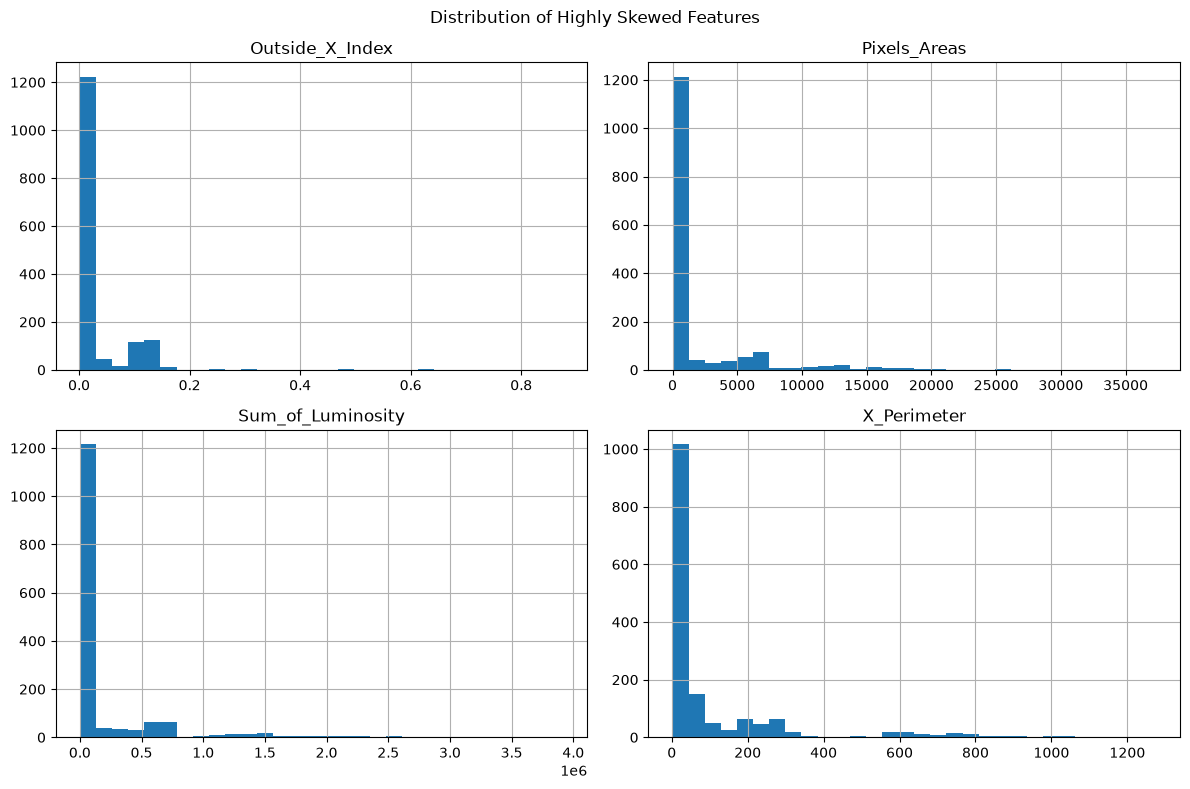

In [23]:
features_to_plot = [
    "Outside_X_Index",
    "Pixels_Areas",
    "Sum_of_Luminosity",
    "X_Perimeter"
]

X_train[features_to_plot].hist(
    bins=30,
    figsize=(12, 8)
)

plt.suptitle("Distribution of Highly Skewed Features")
plt.tight_layout()
plt.show()

#### Feature 분포 확인
Outside_X_Index, Pixels_Areas, Sum_of_Luminosity, X_Perimeter 등에서 높은 양의 왜도가 확인되었으며, 히스토그램에서도 대부분의 관측치가 작은 값에 집중되고 일부 큰 값까지 오른쪽 꼬리가 이어지는 분포가 나타났다. 다만 현재까지 해당 값들을 측정 오류나 비정상 관측치로 판단할 근거는 확인되지 않았다. 특히 면적·둘레·밝기 합계 등 결함 크기와 관련된 Feature에서 이러한 특성이 함께 나타나므로, 극단값을 일괄 제거하지 않고 이후 결함 유형별 분포를 확인한다.

Feature 간 값의 범위 차이가 크므로 scale-sensitive 모델에서는 Scaling을 적용할 필요가 있다. 로그 변환 Feature는 분포의 왜도를 완화하기 위한 변수로 Scaling과 목적이 다르므로, 로그 Feature를 사용하더라도 필요에 따라 Scaling을 별도로 적용한다.

In [24]:
import numpy as np

# Feature 간 Pearson 상관계수
corr = X_train.corr(method="pearson")

# 자기 자신 및 중복 조합을 제외하고 Feature 쌍으로 변환
upper = corr.where(
    np.triu(np.ones(corr.shape), k=1).astype(bool)
)

corr_pairs = (
    upper.stack()
         .reset_index()
)

corr_pairs.columns = ["Feature_1", "Feature_2", "Correlation"]
corr_pairs["Abs_Correlation"] = corr_pairs["Correlation"].abs()

# 절댓값 기준 내림차순
corr_pairs = corr_pairs.sort_values(
    "Abs_Correlation",
    ascending=False
)

display(corr_pairs.head(20))

,Feature_1,Feature_2,Correlation,Abs_Correlation
309,TypeOfSteel_A300,TypeOfSteel_A400,-1.0000,1.0000
57,Y_Minimum,Y_Maximum,1.0000,1.0000
115,Pixels_Areas,Sum_of_Luminosity,0.9966,0.9966
1,X_Minimum,X_Maximum,0.9875,0.9875
142,X_Perimeter,Sum_of_Luminosity,0.9613,0.9613
113,Pixels_Areas,X_Perimeter,0.9603,0.9603
141,X_Perimeter,Y_Perimeter,0.9523,0.9523
169,Y_Perimeter,Sum_of_Luminosity,0.9350,0.9350
114,Pixels_Areas,Y_Perimeter,0.9334,0.9334
589,LogOfAreas,Log_X_Index,0.8909,0.8909


In [25]:
pairs = [
    ("Pixels_Areas", "LogOfAreas"),
    ("X_Minimum", "X_Maximum"),
    ("Y_Minimum", "Y_Maximum")
]

for col1, col2 in pairs:
    pearson = X_train[col1].corr(X_train[col2], method="pearson")
    spearman = X_train[col1].corr(X_train[col2], method="spearman")

    print(f"{col1} ↔ {col2}")
    print(f"  Pearson : {pearson:.4f}")
    print(f"  Spearman: {spearman:.4f}\n")

Pixels_Areas ↔ LogOfAreas
  Pearson : 0.8015
  Spearman: 1.0000

X_Minimum ↔ X_Maximum
  Pearson : 0.9875
  Spearman: 0.9461

Y_Minimum ↔ Y_Maximum
  Pearson : 1.0000
  Spearman: 1.0000



#### Feature 간 관계 확인
Pearson 상관분석 결과 위치 변수, 결함 크기 관련 변수 및 강종 변수 사이에서 높은 상관관계가 확인되었다. 특히 TypeOfSteel_A300과 TypeOfSteel_A400은 완전한 음의 상관관계(-1.000)를 보였으며, Y_Minimum과 Y_Maximum도 거의 동일하게 움직였다. 또한 Pixels_Areas, Sum_of_Luminosity, X/Y_Perimeter 등 결함 크기 관련 변수 사이에서 강한 양의 상관관계가 나타났다.
Pixels_Areas와 LogOfAreas는 Pearson 상관계수는 0.8015였으나 Spearman 상관계수는 1.0000으로 나타났다. 이는 로그 변환으로 인해 선형 관계는 완화되었지만 값의 순서는 완전히 유지되는 단조 관계임을 보여준다. 따라서 Feature 중복 가능성을 판단할 때 Pearson뿐 아니라 변수의 정의와 Spearman 관계도 함께 고려할 필요가 있다.

In [26]:
from scipy.stats import kruskal

results = []

for feature in X_train.columns:
    groups = [
        X_train.loc[y_train == cls, feature]
        for cls in y_train.unique()
    ]

    stat, p_value = kruskal(*groups)

    results.append({
        "Feature": feature,
        "Kruskal_H": stat,
        "p_value": p_value
    })

kruskal_result = (
    pd.DataFrame(results)
    .sort_values("Kruskal_H", ascending=False)
    .reset_index(drop=True)
)

display(kruskal_result)

,Feature,Kruskal_H,p_value
0,Sum_of_Luminosity,656.8392,0.0000
1,Outside_X_Index,647.5910,0.0000
2,Log_X_Index,637.8982,0.0000
3,LogOfAreas,625.8363,0.0000
4,Pixels_Areas,625.8363,0.0000
5,Y_Perimeter,588.5976,0.0000
6,X_Perimeter,584.7961,0.0000
7,Edges_Y_Index,567.4138,0.0000
8,SigmoidOfAreas,564.0784,0.0000
9,Log_Y_Index,540.4094,0.0000


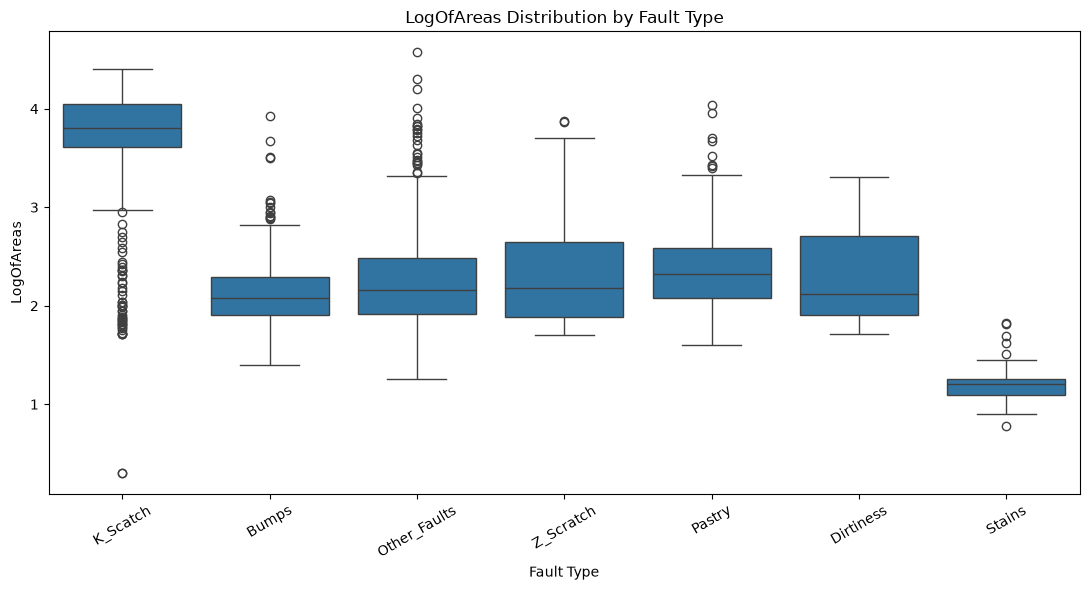

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

eda_train = X_train.copy()
eda_train["Fault_Type"] = y_train

plt.figure(figsize=(11, 6))

sns.boxplot(
    data=eda_train,
    x="Fault_Type",
    y="LogOfAreas"
)

plt.title("LogOfAreas Distribution by Fault Type")
plt.xlabel("Fault Type")
plt.ylabel("LogOfAreas")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

#### 결함 면적과 Class의 관계
LogOfAreas의 클래스별 분포를 비교한 결과, K_Scatch는 다른 클래스보다 전반적으로 큰 값을, Stains는 매우 작은 값을 보였다. 반면 Bumps, Other_Faults, Z_Scratch, Pastry, Dirtiness는 분포가 상당 부분 중첩되었다. 따라서 결함 면적은 특히 K_Scatch와 Stains를 구분하는 데 유용한 정보일 가능성이 있으나, 면적 정보만으로 전체 7개 클래스를 구분하기는 어려울 것으로 판단된다. Other_Faults는 비교적 넓은 분포를 보여 내부 이질성 가능성을 이후 추가 탐색한다.

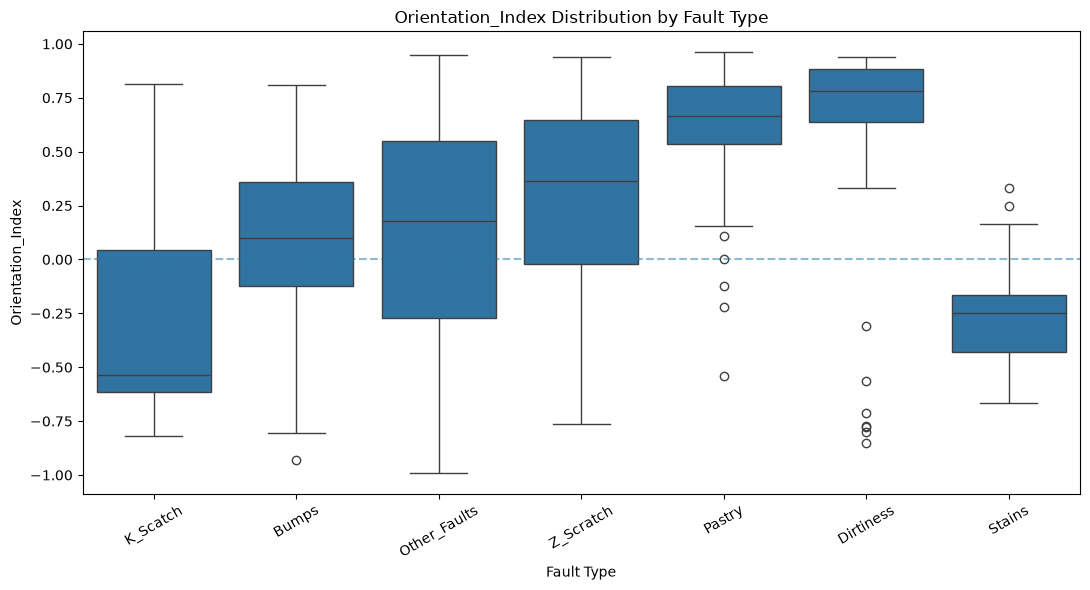

In [28]:
plt.figure(figsize=(11, 6))

sns.boxplot(
    data=eda_train,
    x="Fault_Type",
    y="Orientation_Index"
)

plt.axhline(0, linestyle="--", alpha=0.5)

plt.title("Orientation_Index Distribution by Fault Type")
plt.xlabel("Fault Type")
plt.ylabel("Orientation_Index")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

#### 결함 방향성과 Class의 관계
Orientation_Index는 결함 유형별로 뚜렷한 분포 차이를 보였다. Pastry와 Dirtiness는 높은 양의 값에 집중된 반면, K_Scatch와 Stains는 주로 음의 영역에 분포하였다. 앞선 면적 분석에서 분포가 겹쳤던 일부 클래스가 방향성에서는 서로 다른 특성을 보여, 단일 Feature보다는 크기·형상·방향 등 여러 정보를 함께 활용할 필요성이 확인되었다. Other_Faults는 방향성에서도 넓은 분포를 보여 내부 이질성 가능성을 추후 추가 탐색한다.

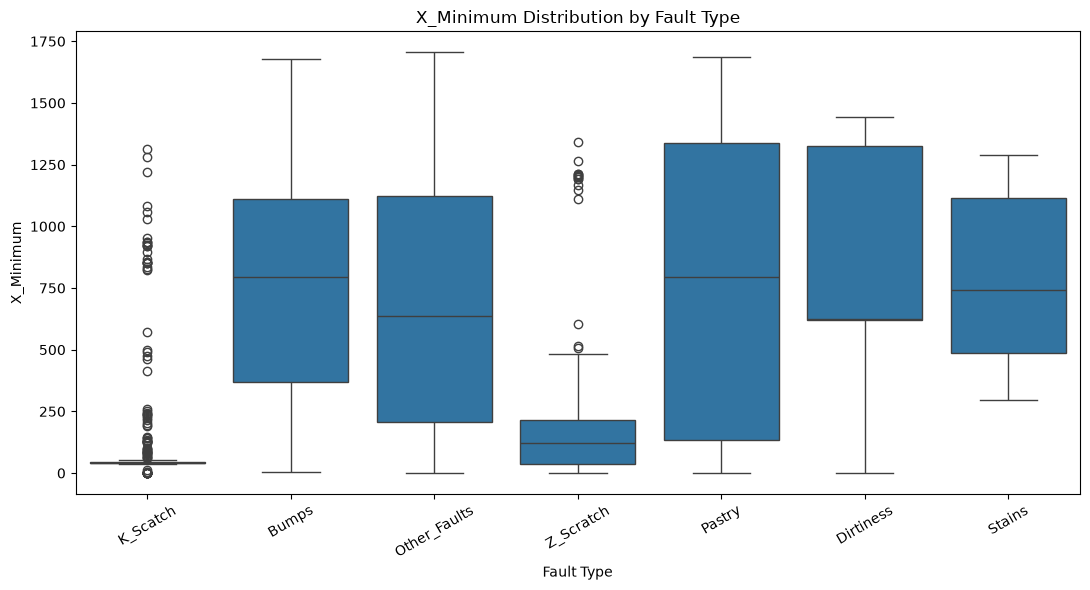

In [29]:
plt.figure(figsize=(11, 6))

sns.boxplot(
    data=eda_train,
    x="Fault_Type",
    y="X_Minimum"
)

plt.title("X_Minimum Distribution by Fault Type")
plt.xlabel("Fault Type")
plt.ylabel("X_Minimum")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

#### 결함 위치와 Class의 관계
X_Minimum의 클래스별 분포를 비교한 결과, K_Scatch는 대부분 매우 낮은 X 위치에 집중되었으며 Z_Scratch도 상대적으로 낮은 위치에 분포하였다. 반면 다른 클래스들은 비교적 높은 위치 또는 넓은 범위에 분포하였다. 따라서 결함의 가로 위치는 일부 결함 유형을 구분하는 데 유용한 정보일 가능성이 있다. 특히 앞서 확인한 크기 및 방향성 Feature와 함께 고려할 경우 클래스별 특성이 보다 명확하게 나타났다. Other_Faults는 위치에서도 넓은 분포를 보여 내부 이질성 가능성을 추가 확인할 필요가 있다.

,A400,A300
Fault_Type,,
Bumps,30.8400,69.1600
Dirtiness,79.5500,20.4500
K_Scatch,100.0000,0.0000
Other_Faults,60.2200,39.7800
Pastry,69.0500,30.9500
Stains,100.0000,0.0000
Z_Scratch,9.8700,90.1300


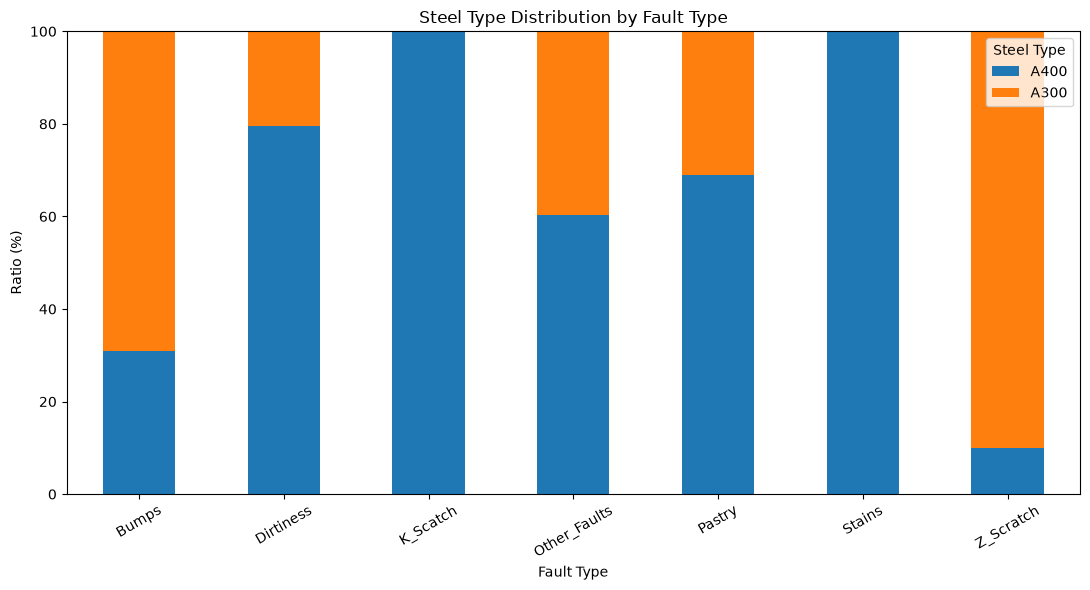

In [31]:
# 결함 Class별 강종 비율
steel_ratio = pd.crosstab(
    eda_train["Fault_Type"],
    eda_train["TypeOfSteel_A300"],
    normalize="index"
) * 100

steel_ratio.columns = ["A400", "A300"]

display(steel_ratio.round(2))

steel_ratio.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 6)
)

plt.title("Steel Type Distribution by Fault Type")
plt.xlabel("Fault Type")
plt.ylabel("Ratio (%)")
plt.xticks(rotation=30)
plt.legend(title="Steel Type")
plt.tight_layout()
plt.show()

In [32]:
classes = y_train.unique()

relative_iqr = {}

for cls in classes:
    class_data = X_train.loc[y_train == cls]

    class_iqr = (
        class_data.quantile(0.75)
        - class_data.quantile(0.25)
    )

    total_iqr = (
        X_train.quantile(0.75)
        - X_train.quantile(0.25)
    )

    relative_iqr[cls] = class_iqr / total_iqr

relative_iqr_df = pd.DataFrame(relative_iqr)

# IQR이 0인 Feature에서 발생하는 inf/NaN 제외
relative_iqr_df = relative_iqr_df.replace([np.inf, -np.inf], np.nan)

# 클래스별 상대 IQR 중앙값
iqr_summary = (
    relative_iqr_df.median()
    .sort_values(ascending=False)
    .to_frame("Median_Relative_IQR")
)

display(iqr_summary)

,Median_Relative_IQR
Other_Faults,0.9816
K_Scatch,0.7352
Pastry,0.7167
Dirtiness,0.6487
Bumps,0.6219
Z_Scratch,0.5858
Stains,0.2241


In [33]:
other_iqr = (
    relative_iqr_df["Other_Faults"]
    .sort_values(ascending=False)
    .to_frame("Other_Faults_Relative_IQR")
)

display(other_iqr)

other_compare = pd.DataFrame({
    "Other_Faults": relative_iqr_df["Other_Faults"],
    "Other_Classes_Median": (
        relative_iqr_df
        .drop(columns="Other_Faults")
        .median(axis=1)
    )
})

other_compare["Ratio"] = (
    other_compare["Other_Faults"]
    / other_compare["Other_Classes_Median"]
)

other_compare = other_compare.sort_values(
    "Ratio",
    ascending=False
)

display(other_compare)

,Other_Faults_Relative_IQR
Steel_Plate_Thickness,2.4937
Maximum_of_Luminosity,1.3125
Luminosity_Index,1.3055
Length_of_Conveyer,1.1190
Empty_Index,1.1048
X_Maximum,1.0501
Square_Index,1.0210
Y_Minimum,1.0060
Y_Maximum,1.0059
TypeOfSteel_A300,1.0000


,Other_Faults,Other_Classes_Median,Ratio
TypeOfSteel_A300,1.0000,0.0000,inf
TypeOfSteel_A400,1.0000,0.0000,inf
Length_of_Conveyer,1.1190,0.0865,12.9406
Steel_Plate_Thickness,2.4937,0.2500,9.9750
Outside_Global_Index,1.0000,0.3125,3.2000
Edges_Y_Index,0.7136,0.2449,2.9140
Orientation_Index,0.9816,0.4501,2.1807
Minimum_of_Luminosity,0.6989,0.3750,1.8636
Outside_X_Index,0.5853,0.3353,1.7456
Luminosity_Index,1.3055,0.7789,1.6761


#### Other_Faults 내부 특성 탐색
Other_Faults는 27개 Feature의 상대 IQR 중앙값이 0.982로 7개 클래스 중 가장 높게 나타났다. Feature별 비교에서는 특히 Length_of_Conveyer, Steel_Plate_Thickness, 방향·형상 및 일부 밝기 관련 Feature에서 다른 클래스보다 높은 내부 변동성이 확인되었다. 반면 Pixels_Areas, Y_Perimeter, Sum_of_Luminosity 등 일부 크기 관련 Feature에서는 다른 클래스보다 변동성이 크지 않았다. 따라서 Other_Faults가 모든 특성에서 일관되게 이질적이라고 보기는 어렵지만, 일부 특성에서 상대적으로 다양한 패턴을 포함할 가능성이 있다. 다만 현재 분석만으로 내부에 여러 하위 결함 유형이 존재한다고 판단할 수는 없다.

#### EDA 기반 모델링 전 결정
Train 데이터에는 결측치와 중복 행이 없어 별도의 처리가 필요하지 않았다. 일부 연속형 Feature에서 높은 왜도와 극단값이 확인되었으나 데이터 오류로 판단할 근거가 없으며 결함 특성 자체를 나타낼 가능성이 있어 일괄 제거하지 않는다.
Feature 간 Scale 차이가 크므로 Logistic Regression 등 scale-sensitive 모델에서는 Scaling을 적용한다. TypeOfSteel_A300/A400, 위치 변수, 크기·둘레·밝기 관련 변수 및 원본-로그 변수에서 높은 중복성이 확인되었으나, EDA만으로 대규모 Feature 제거를 결정하지 않고 모델링 과정에서 필요성을 검토한다. 특히 강종 정보는 Target과 뚜렷한 연관성이 확인되어 정보 자체는 유지한다.
클래스별 EDA에서는 단일 Feature보다 크기·위치·형상·강종 등 여러 Feature의 조합이 결함 유형 구분에 활용될 가능성이 확인되었다. Other_Faults는 일부 Feature에서 높은 내부 변동성을 보였으나 별도의 하위 클래스로 구분할 근거는 확인되지 않았다.
Baseline에서는 불균형 처리를 적용하지 않은 상태에서 동일한 5-fold Stratified CV와 Macro F1을 기준으로 모델을 비교하며, 클래스별 Precision·Recall·F1을 함께 확인하여 소수 클래스 및 Other_Faults의 실제 분류 성능을 확인한다.